# 3. CNN Training with PyTorch

This notebook builds PyTorch datasets and data loaders, defines a small convolutional neural network, handles class imbalance with weighted cross-entropy, and trains the model using the lot-aware data splits prepared in Chapter 2.

In [1]:
from pathlib import Path
import sys
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open Jupyter from the "
        "'wafer-map-defect-classification' folder."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

MODEL_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Training device:", DEVICE)
print("Project root:", PROJECT_ROOT)

PyTorch version: 2.14.1
Training device: mps
Project root: <LOCAL_PATH>


## 3.1 Load Raw Data and Split Manifests

In [2]:
from src.data_loading import load_wm811k
from src.preprocessing import preprocess_wafer_map


DATA_ARCHIVE = RAW_DATA_DIR / "WM811K_source.zip"

wm811k = load_wm811k(DATA_ARCHIVE)

train_manifest = pd.read_csv(
    PROCESSED_DATA_DIR / "train_manifest.csv"
)

validation_manifest = pd.read_csv(
    PROCESSED_DATA_DIR / "validation_manifest.csv"
)

test_manifest = pd.read_csv(
    PROCESSED_DATA_DIR / "test_manifest.csv"
)

with open(
    PROCESSED_DATA_DIR / "class_mapping.json",
    "r",
    encoding="utf-8",
) as file:
    class_to_index = json.load(file)

CLASS_NAMES = [
    class_name
    for class_name, class_index in sorted(
        class_to_index.items(),
        key=lambda item: item[1],
    )
]

print("Raw dataset shape:", wm811k.shape)
print("Training samples:", len(train_manifest))
print("Validation samples:", len(validation_manifest))
print("Test samples:", len(test_manifest))
print("Class order:", CLASS_NAMES)

Raw dataset shape: (811457, 6)
Training samples: 43486
Validation samples: 10869
Test samples: 118595
Class order: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'none']


## 3.2 Build the PyTorch Dataset

In [3]:
class WaferMapDataset(Dataset):
    """Provide preprocessed wafer maps and labels to PyTorch."""

    def __init__(self, manifest, raw_data):
        self.manifest = manifest.reset_index(drop=True)
        self.raw_data = raw_data

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]

        source_index = int(row["source_index"])
        wafer_map = self.raw_data.at[source_index, "waferMap"]

        image = preprocess_wafer_map(wafer_map)

        label = torch.tensor(
            int(row["label_index"]),
            dtype=torch.long,
        )

        return image, label

In [4]:
train_dataset = WaferMapDataset(
    train_manifest,
    wm811k,
)

validation_dataset = WaferMapDataset(
    validation_manifest,
    wm811k,
)

test_dataset = WaferMapDataset(
    test_manifest,
    wm811k,
)

first_image, first_label = train_dataset[0]

print("Training dataset length:", len(train_dataset))
print("Validation dataset length:", len(validation_dataset))
print("Test dataset length:", len(test_dataset))

print("\nFirst image type:", type(first_image))
print("First image shape:", first_image.shape)
print("First image data type:", first_image.dtype)

print("\nFirst numeric label:", first_label.item())
print("First class name:", CLASS_NAMES[first_label.item()])

Training dataset length: 43486
Validation dataset length: 10869
Test dataset length: 118595

First image type: <class 'torch.Tensor'>
First image shape: torch.Size([1, 64, 64])
First image data type: torch.float32

First numeric label: 8
First class name: none


## 3.3 Build the PyTorch Data Loaders

In [5]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

batch_images, batch_labels = next(iter(train_loader))

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(validation_loader))
print("Number of test batches:", len(test_loader))

print("\nImage batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)

print("\nClass counts in the first training batch:")
print(
    torch.bincount(
        batch_labels,
        minlength=len(CLASS_NAMES),
    )
)

Number of training batches: 340
Number of validation batches: 85
Number of test batches: 927

Image batch shape: torch.Size([128, 1, 64, 64])
Label batch shape: torch.Size([128])

Class counts in the first training batch:
tensor([10,  2,  6, 25,  2,  0,  5,  1, 77])


## 3.4 Define a Small Convolutional Neural Network

In [6]:
class WaferMapCNN(nn.Module):
    """A small CNN for nine-class wafer-map classification."""

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=0.30)
        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(x)
        x = self.classifier(x)

        return x

In [7]:
model = WaferMapCNN(
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

batch_images = batch_images.to(DEVICE)

with torch.no_grad():
    batch_outputs = model(batch_images)

number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(model)

print("\nNumber of model parameters:",
      f"{number_of_parameters:,}")

print("Input batch shape:", batch_images.shape)
print("Output batch shape:", batch_outputs.shape)

WaferMapCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (global_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_feature

## 3.5 Define Class-Weighted Loss and Optimizer

In [8]:
training_class_counts = (
    train_manifest["label_index"]
    .value_counts()
    .sort_index()
)

class_weights = (
    len(train_manifest)
    / (
        len(CLASS_NAMES)
        * training_class_counts.values
    )
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

weight_table = pd.DataFrame(
    {
        "class_name": CLASS_NAMES,
        "training_count": training_class_counts.values,
        "class_weight": class_weights.cpu().numpy(),
    }
)

display(weight_table)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001,
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

,class_name,training_count,class_weight
0,Center,2769,1.744954
1,Donut,327,14.776079
2,Edge-Loc,1934,2.498334
3,Edge-Ring,6843,0.706091
4,Loc,1296,3.728224
5,Near-full,44,109.813133
6,Random,487,9.921515
7,Scratch,400,12.079445
8,none,29386,0.164424


Loss function: CrossEntropyLoss()
Optimizer: Adam


## 3.6 Define the Training and Validation Functions

In [9]:
from sklearn.metrics import f1_score


def train_one_epoch(model, data_loader, criterion, optimizer, device):
    """Train the model for one complete pass over the training set."""

    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    average_loss = total_loss / len(data_loader.dataset)

    accuracy = np.mean(
        np.array(all_labels) == np.array(all_predictions)
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0,
    )

    return average_loss, accuracy, macro_f1


def evaluate_model(model, data_loader, criterion, device):
    """Evaluate the model without updating its parameters."""

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += loss.item() * images.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    average_loss = total_loss / len(data_loader.dataset)

    accuracy = np.mean(
        np.array(all_labels) == np.array(all_predictions)
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0,
    )

    return average_loss, accuracy, macro_f1

In [10]:
import time


start_time = time.time()

train_loss, train_accuracy, train_macro_f1 = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    DEVICE,
)

validation_loss, validation_accuracy, validation_macro_f1 = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
)

elapsed_time = time.time() - start_time

print("Epoch 1")
print(
    f"Train loss: {train_loss:.4f} | "
    f"Train accuracy: {train_accuracy:.4f} | "
    f"Train macro F1: {train_macro_f1:.4f}"
)

print(
    f"Validation loss: {validation_loss:.4f} | "
    f"Validation accuracy: {validation_accuracy:.4f} | "
    f"Validation macro F1: {validation_macro_f1:.4f}"
)

print(f"Elapsed time: {elapsed_time:.1f} seconds")

Epoch 1
Train loss: 1.4174 | Train accuracy: 0.6056 | Train macro F1: 0.3532
Validation loss: 1.0096 | Validation accuracy: 0.8046 | Validation macro F1: 0.4359
Elapsed time: 11.2 seconds


## 3.7 Train the CNN and Save the Best Checkpoint

In [11]:
MAX_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 4

history = {
    "train_loss": [train_loss],
    "validation_loss": [validation_loss],
    "train_accuracy": [train_accuracy],
    "validation_accuracy": [validation_accuracy],
    "train_macro_f1": [train_macro_f1],
    "validation_macro_f1": [validation_macro_f1],
}

best_validation_macro_f1 = validation_macro_f1
best_epoch = 1
epochs_without_improvement = 0

best_model_path = MODEL_DIR / "best_wafer_map_cnn.pt"

torch.save(
    {
        "epoch": 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "validation_macro_f1": validation_macro_f1,
        "class_to_index": class_to_index,
        "target_size": 64,
    },
    best_model_path,
)

for epoch in range(2, MAX_EPOCHS + 1):
    start_time = time.time()

    train_loss, train_accuracy, train_macro_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE,
    )

    validation_loss, validation_accuracy, validation_macro_f1 = evaluate_model(
        model,
        validation_loader,
        criterion,
        DEVICE,
    )

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_accuracy"].append(validation_accuracy)
    history["train_macro_f1"].append(train_macro_f1)
    history["validation_macro_f1"].append(validation_macro_f1)

    if validation_macro_f1 > best_validation_macro_f1:
        best_validation_macro_f1 = validation_macro_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_macro_f1": validation_macro_f1,
                "class_to_index": class_to_index,
                "target_size": 64,
            },
            best_model_path,
        )

        checkpoint_status = "saved"
    else:
        epochs_without_improvement += 1
        checkpoint_status = "not saved"

    elapsed_time = time.time() - start_time

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_macro_f1:.4f} | "
        f"Validation loss: {validation_loss:.4f} | "
        f"Validation macro F1: {validation_macro_f1:.4f} | "
        f"{checkpoint_status} | "
        f"{elapsed_time:.1f}s"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping triggered after epoch {epoch}."
        )
        break

print("\nBest epoch:", best_epoch)
print(
    "Best validation macro F1:",
    f"{best_validation_macro_f1:.4f}",
)
print("Best model saved to:", best_model_path)

Epoch 02 | Train loss: 1.0457 | Train macro F1: 0.5066 | Validation loss: 0.8387 | Validation macro F1: 0.6074 | saved | 9.0s
Epoch 03 | Train loss: 0.9060 | Train macro F1: 0.5464 | Validation loss: 0.9308 | Validation macro F1: 0.4875 | not saved | 8.9s
Epoch 04 | Train loss: 0.8478 | Train macro F1: 0.5758 | Validation loss: 1.2835 | Validation macro F1: 0.4687 | not saved | 8.6s
Epoch 05 | Train loss: 0.8075 | Train macro F1: 0.5818 | Validation loss: 0.7111 | Validation macro F1: 0.6076 | saved | 8.5s
Epoch 06 | Train loss: 0.7633 | Train macro F1: 0.6061 | Validation loss: 0.5000 | Validation macro F1: 0.6716 | saved | 8.6s
Epoch 07 | Train loss: 0.7239 | Train macro F1: 0.6198 | Validation loss: 0.5747 | Validation macro F1: 0.7041 | saved | 8.5s
Epoch 08 | Train loss: 0.6998 | Train macro F1: 0.6295 | Validation loss: 0.8486 | Validation macro F1: 0.6045 | not saved | 8.5s
Epoch 09 | Train loss: 0.6836 | Train macro F1: 0.6349 | Validation loss: 0.6262 | Validation macro F1: 0.

## 3.8 Review Training History and Reload the Best Model

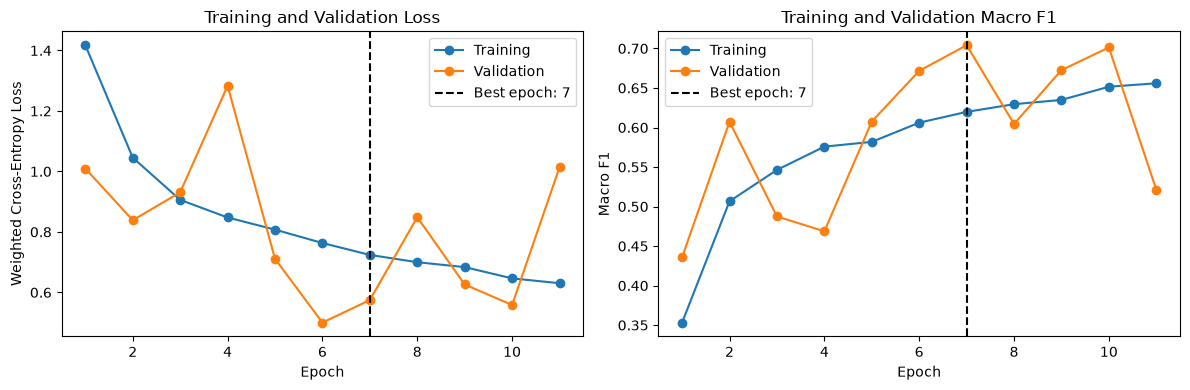

Training curve saved to: <LOCAL_PATH>


In [12]:
completed_epochs = range(
    1,
    len(history["train_loss"]) + 1,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    completed_epochs,
    history["train_loss"],
    marker="o",
    label="Training",
)

axes[0].plot(
    completed_epochs,
    history["validation_loss"],
    marker="o",
    label="Validation",
)

axes[0].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted Cross-Entropy Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()

axes[1].plot(
    completed_epochs,
    history["train_macro_f1"],
    marker="o",
    label="Training",
)

axes[1].plot(
    completed_epochs,
    history["validation_macro_f1"],
    marker="o",
    label="Validation",
)

axes[1].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Training and Validation Macro F1")
axes[1].legend()

plt.tight_layout()

training_curve_path = (
    FIGURES_DIR / "03_training_history.png"
)

plt.savefig(
    training_curve_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Training curve saved to:", training_curve_path)

In [13]:
checkpoint = torch.load(
    best_model_path,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_validation_results = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
)

print("Loaded checkpoint epoch:", checkpoint["epoch"])

print(
    "Checkpoint validation macro F1:",
    f"{checkpoint['validation_macro_f1']:.4f}",
)

print(
    "Recomputed validation macro F1:",
    f"{best_validation_results[2]:.4f}",
)

Loaded checkpoint epoch: 7
Checkpoint validation macro F1: 0.7041
Recomputed validation macro F1: 0.7041


In [14]:
%%writefile ../src/model.py

"""CNN architecture for WM-811K wafer-map classification."""

import torch
import torch.nn as nn


class WaferMapCNN(nn.Module):
    """A small CNN for nine-class wafer-map classification."""

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=0.30)
        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(x)
        x = self.classifier(x)

        return x

Writing ../src/model.py


In [15]:
training_history = pd.DataFrame(
    {
        "epoch": list(completed_epochs),
        **history,
    }
)

training_history.to_csv(
    MODEL_DIR / "training_history.csv",
    index=False,
)

print(training_history)
print("\nSaved:", MODEL_DIR / "training_history.csv")

    epoch  train_loss  validation_loss  train_accuracy  validation_accuracy  \
0       1    1.417427         1.009557        0.605620             0.804582   
1       2    1.045670         0.838652        0.749690             0.780201   
2       3    0.906012         0.930826        0.774801             0.665103   
3       4    0.847778         1.283464        0.792669             0.443003   
4       5    0.807518         0.711136        0.800143             0.768516   
5       6    0.763335         0.500024        0.816700             0.892814   
6       7    0.723938         0.574705        0.827830             0.927500   
7       8    0.699817         0.848608        0.827094             0.705125   
8       9    0.683610         0.626159        0.837764             0.790965   
9      10    0.646422         0.558396        0.839167             0.887570   
10     11    0.630339         1.013440        0.848480             0.595823   

    train_macro_f1  validation_macro_f1  
0        

## 3.9 Training Summary

- A custom three-block CNN with 24,105 trainable parameters was implemented in PyTorch.
- Wafer maps were loaded in batches of 128 using custom `Dataset` and `DataLoader` objects.
- Class-weighted cross-entropy was used to reduce the dominance of the majority `none` class.
- Adam optimization was applied with a learning rate of 0.001 and weight decay of 0.0001.
- Model selection was based on validation macro F1 rather than accuracy.
- Early stopping was triggered at epoch 11 after four epochs without improvement.
- The best checkpoint was obtained at epoch 7 with a validation macro F1 of 0.7041.
- The saved checkpoint was reloaded and reproduced the same validation macro F1.
- The untouched official test set will be evaluated only in the final evaluation notebook.